# Your first additive models

This notebook teaches NAMpy's common modeling language once. Statistical
GAMs and neural additive models use different fitting algorithms, but
they share an estimator interface and an additive explanation contract.
Later notebooks can therefore focus on model-specific theory rather than
repeating `fit`, prediction, reconstruction, and sklearn.


Prerequisites: basic Python and pandas. Allow about a minute on CPU; the
execution note records the measured runtime and tested versions. The model
comparison uses held-out rows, and cross-validation reports held-out fold scores.

**Core walkthrough:** regression, test predictions, residuals, and additive
contributions (through “Inspect additive contributions”). Stop there for a
complete first analysis. Classification/link functions, calibration, and
cross-validation are optional extensions below. Then use the
[real-data workflow](05_real_data_classification.ipynb) before choosing a branch.


**Execution environment:** nampy 0.3.0, numpy 1.26.4, scikit-learn 1.9.0, torch 2.14.1+cpu, lightning 2.6.6. Python 3.12.13; source revision `638ae3d3aeb991c46a6e144904357977c9c7fcac`; source-content SHA256 `cb792c506d7ebd25c1ad3a6f975f376c8754fee9c0dc514dd085dc0f70fc01ca` (includes local source changes); elapsed 19.6 seconds on this CPU. Runtime varies by hardware.

## 1. Additive models as structured predictors

An additive model builds a prediction from separate feature effects:

$$\eta(x)=\beta_0+\sum_{j=1}^{p} f_j(x_j),\qquad \mu(x)=g^{-1}\{\eta(x)\}.$$

Here $\beta_0$ is a baseline, $f_j$ describes how feature $j$ contributes,
and $g$ connects the conditional mean to the additive predictor. For the
Gaussian regression below, the identity link gives $\mu(x)=\eta(x)$.
The model can therefore learn curved relationships while keeping each
feature's contribution available for inspection. Main-effect additivity
assumes that a feature's contribution does not depend on other feature values;
an explicit interaction relaxes that assumption for a chosen group of inputs.


## 2. Data for the examples

The response below is generated by adding known nonlinear effects and
random noise. This lets us distinguish recovery of the underlying relationship
from fitting individual noisy observations. A held-out split estimates how
well the learned relationship predicts new rows; training fit alone cannot
answer that question.

The initial four-panel figure is a preview of the regression, classification,
changing-spread, and interaction questions used in later chapters. Only the
main-effects regression dataset is needed for the core walkthrough.


In [1]:
import logging
import warnings
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message="You called.*self.log.*logger=True.*")
from pathlib import Path
import tempfile
import time
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message=".*does not have many workers.*")
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#2563EB", "#F97316", "#10B981", "#8B5CF6", "#EF4444"]

N_SAMPLES = 1000
MAX_EPOCHS = 100
RANDOM_STATE = 7
CHECKPOINT_ROOT = Path(tempfile.mkdtemp(prefix="nampy-notebook-"))

NEURAL_FIT_KWARGS = {
    "max_epochs": MAX_EPOCHS,
    "batch_size": 128,
    "lr": 1e-2,
    "patience": 15,
    "random_state": RANDOM_STATE,
    "checkpoint_path": CHECKPOINT_ROOT,
    "logger": False,
    "enable_progress_bar": False,
    "enable_model_summary": False,
    "num_sanity_val_steps": 0,
}

rng = np.random.default_rng(RANDOM_STATE)

n = N_SAMPLES
x1 = rng.uniform(-1.0, 1.0, n)
x2 = rng.normal(size=n)
group = pd.Categorical(rng.choice(["a", "b", "c"], size=n))

X = pd.DataFrame({"x1": x1, "x2": x2, "group": group})
main_signal = np.sin(np.pi * x1) + 0.35 * x2**2 + 0.30 * (group == "b")
y_reg = main_signal + rng.normal(0.0, 0.18, n)

logit = -0.3 + 1.8 * np.sin(np.pi * x1) - 0.7 * x2 + 0.5 * (group == "c")
p_binary = 1.0 / (1.0 + np.exp(-logit))
y_binary = rng.binomial(1, p_binary)

sigma = np.exp(-1.1 + 0.55 * (x2 - x2.mean()))
y_hetero = np.sin(np.pi * x1) + sigma * rng.normal(size=n)

X_sparse = pd.DataFrame({f"x{j}": rng.normal(size=n) for j in range(1, 7)})
y_sparse = (
    np.sin(X_sparse["x1"])
    + 0.8 * X_sparse["x2"] * X_sparse["x3"]
    + rng.normal(0.0, 0.2, n)
)

datasets = {
    "nonlinear regression": (X, y_reg),
    "binary classification": (X, y_binary),
    "heteroscedastic regression": (X[["x1", "x2"]], y_hetero),
    "sparse interaction problem": (X_sparse, y_sparse),
}
pd.DataFrame(
    {"dataset": name, "rows": len(features), "features": features.shape[1]}
    for name, (features, target) in datasets.items()
)


,dataset,rows,features
0,nonlinear regression,1000,3
1,binary classification,1000,3
2,heteroscedastic regression,1000,2
3,sparse interaction problem,1000,6


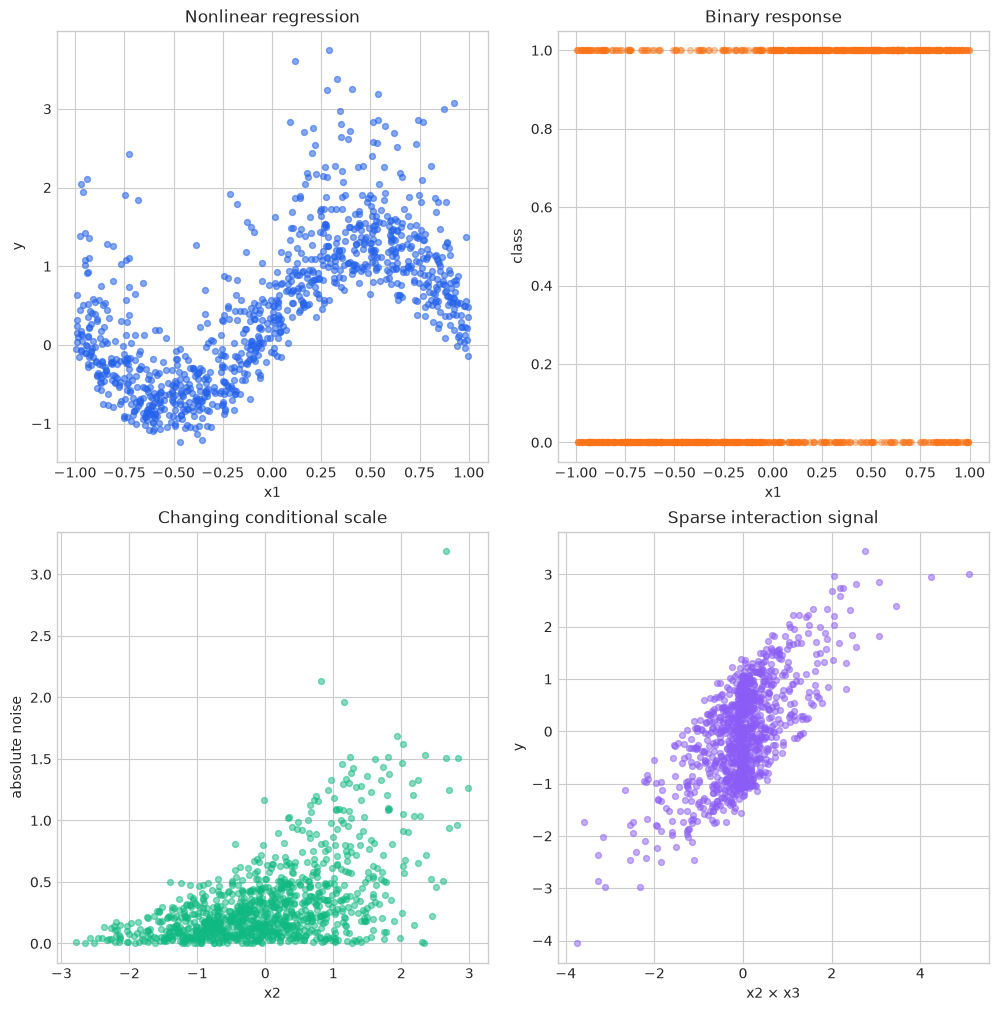

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10), constrained_layout=True)
axes[0, 0].scatter(X["x1"], y_reg, s=18, alpha=0.55, color=COLORS[0])
axes[0, 0].set(title="Nonlinear regression", xlabel="x1", ylabel="y")
axes[0, 1].scatter(X["x1"], y_binary, s=18, alpha=0.35, color=COLORS[1])
axes[0, 1].set(title="Binary response", xlabel="x1", ylabel="class")
axes[1, 0].scatter(X["x2"], np.abs(y_hetero - np.sin(np.pi * x1)), s=18, alpha=0.5, color=COLORS[2])
axes[1, 0].set(title="Changing conditional scale", xlabel="x2", ylabel="absolute noise")
axes[1, 1].scatter(X_sparse["x2"] * X_sparse["x3"], y_sparse, s=18, alpha=0.5, color=COLORS[3])
axes[1, 1].set(title="Sparse interaction signal", xlabel="x2 × x3", ylabel="y")
for plot_axis in fig.axes:
    plot_axis.set_box_aspect(1)
plt.show()
plt.close(fig)


## 3. Fit a statistical and a neural model

A GAM expands each smooth in a basis and controls roughness through a
quadratic penalty. A NAM replaces each univariate smooth with a small
neural network. Both return term-wise contributions, but their inductive
biases differ: spline penalties favor smooth low-curvature functions;
neural networks use architecture, optimization, dropout, and weight
regularization.

Both estimators seek a function close to the observed response, but constrain
it differently. For squared-error regression the data-fit term is
$\frac{1}{n}\sum_i[y_i-\hat\mu(x_i)]^2$. The GAM balances it against spline
roughness; the NAM restricts its feature networks through their architecture
and training. In the figures, similar curves mean the two representations
learned similar relationships, not that their coefficients or uncertainties
are interchangeable.


In [3]:
from sklearn.model_selection import train_test_split
from nampy.models import GAMRegressor, NAMRegressor

train_index, test_index = train_test_split(
    np.arange(n), test_size=0.25, random_state=RANDOM_STATE
)
X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y_reg[train_index], y_reg[test_index]

gam_train = X_train.assign(y=y_train)
gam = GAMRegressor(
    formula="y ~ s(x1, bs='cr', k=9) + s(x2, bs='cr', k=9) + group",
    smoothing_method="reml",
).fit(gam_train)

nam = NAMRegressor(
    layer_sizes=[24, 12],
    dropout=0.0,
    numerical_preprocessing="minmax",
    categorical_preprocessing="one-hot",
)
nam.fit(X_train, y_train, **NEURAL_FIT_KWARGS)

comparison = pd.DataFrame(
    {
        "model": ["GAMRegressor", "NAMRegressor"],
        "test R2": [gam.score(X_test, y_test), nam.score(X_test, y_test)],
        "prediction shape": [gam.predict(X_test).shape, nam.predict(X_test).shape],
    }
)
comparison


,model,test R2,prediction shape
0,GAMRegressor,0.951173,"(250,)"
1,NAMRegressor,0.946653,"(250,)"


### Compare predictions on held-out observations

The diagonal represents a perfect prediction. Scatter around it shows the
remaining prediction error on rows that were not used for fitting.

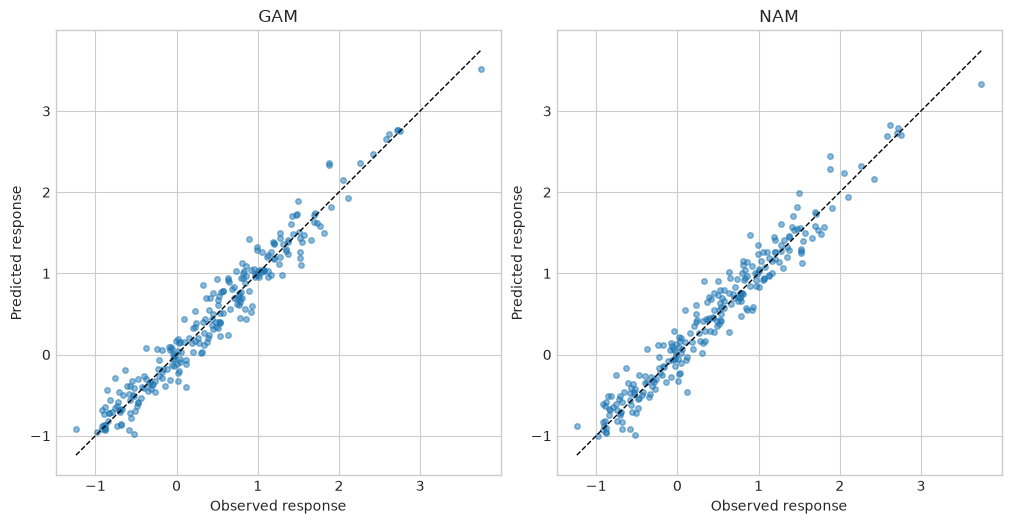

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
limits = [float(y_test.min()), float(y_test.max())]
for axis, (name, fitted) in zip(axes, [("GAM", gam), ("NAM", nam)]):
    axis.scatter(y_test, fitted.predict(X_test), s=16, alpha=0.5)
    axis.plot(limits, limits, color="black", linestyle="--", linewidth=1)
    axis.set(title=name, xlabel="Observed response", ylabel="Predicted response")
for plot_axis in figure.axes:
    plot_axis.set_box_aspect(1)
plt.show()
plt.close(figure)


### Inspect held-out residuals

Residuals are observed minus predicted responses. A trend against fitted
values suggests missing structure, while changing vertical spread suggests
nonconstant response variability. The histogram complements that view by
showing the distribution of prediction errors; neither plot alone proves
that the model assumptions hold.

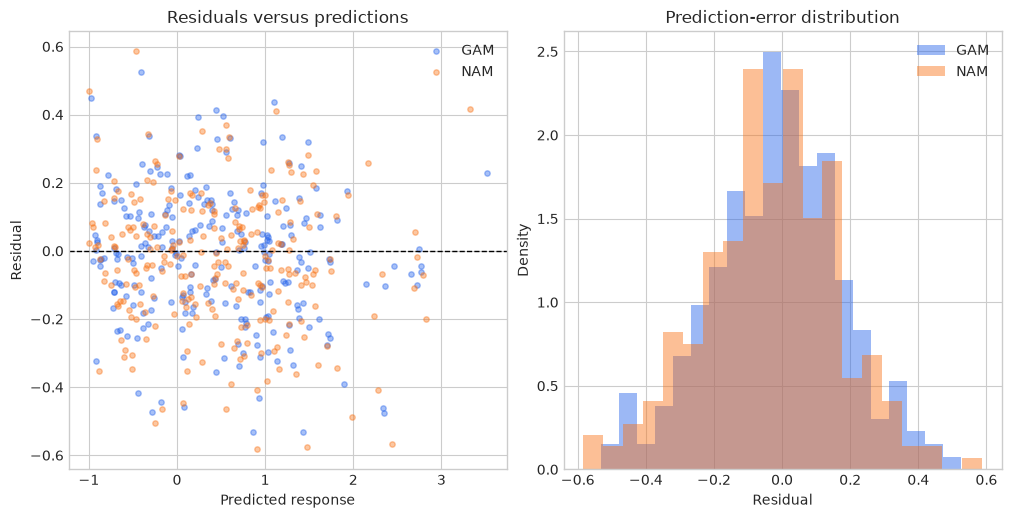

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
for color, (name, fitted) in zip(COLORS, [("GAM", gam), ("NAM", nam)]):
    predicted = fitted.predict(X_test)
    residuals = y_test - predicted
    axes[0].scatter(predicted, residuals, s=15, alpha=0.4, color=color, label=name)
    axes[1].hist(residuals, bins=20, alpha=0.45, density=True, color=color, label=name)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(xlabel="Predicted response", ylabel="Residual", title="Residuals versus predictions")
axes[1].set(xlabel="Residual", ylabel="Density", title="Prediction-error distribution")
for axis in axes:
    axis.set_box_aspect(1)
    axis.legend()
plt.show()
plt.close(figure)


## 4. Fit and predict consistently

NAMpy estimators follow sklearn conventions: constructor arguments are
hyperparameters, `fit` learns trailing-underscore attributes, `predict`
returns task-appropriate outputs, and `score` follows sklearn's
higher-is-better convention. `get_params` and `set_params` make cloning,
pipelines, and searches possible. DataFrame column names become the
fitted feature schema. Prediction validates both names and order.

Sample weights change the empirical objective. They are distinct from an
offset, which changes the linear predictor with a fixed coefficient.


In [6]:
clone_candidate = NAMRegressor(layer_sizes=[8]).set_params(dropout=0.05)
display({
    "feature names": nam.feature_names_in_.tolist(),
    "dropout after set_params": clone_candidate.get_params(deep=False)["dropout"],
})

sample_weight = np.where(X_train["x1"].to_numpy() > 0, 2.0, 1.0)
weighted_gam = GAMRegressor(k=8, basis="cr").fit(
    X_train[["x1", "x2"]], y_train, sample_weight=sample_weight
)


{'feature names': ['x1', 'x2', 'group'], 'dropout after set_params': 0.05}

## 5. Inspect additive contributions

`predict_components` returns an `AdditivePrediction` with `intercept`,
optional `offset`, named `terms`, reconstructed `link`, and final
`response`. `explain_terms` bins those contributions for plotting.
`term_importance` reports mean absolute link-scale contribution;
`interaction_importance` filters interaction terms.

Importance measures magnitude, not causality. Correlated predictors can
redistribute signal, and centering changes the intercept/term allocation
without changing predictions.

A constant can be moved between a feature function and the intercept without
changing predictions. Empirical centering chooses a convention:

$$\tilde f_j(x)=f_j(x)-\frac{1}{n}\sum_i f_j(x_{ij}),\qquad
\tilde\beta_0=\beta_0+\sum_j\frac{1}{n}\sum_i f_j(x_{ij}).$$

A centered effect above zero raises the predictor relative to this reference;
a negative value lowers it. The importance table summarizes
$I_j=\frac{1}{n}\sum_i|\tilde f_j(x_{ij})|$. Read it together with the curves:
a large value describes a large typical contribution, not a direction or
a causal influence.


In [7]:
component_rows = []
for fitted_model in (gam, nam):
    components = fitted_model.predict_components(X_test)
    components.validate_additive_reconstruction(rtol=1e-5, atol=1e-6)
    component_rows.append({"Model": type(fitted_model).__name__,
                           "Terms": len(components.terms), "Reconstruction": "Checked"})
display(pd.DataFrame(component_rows))
display(gam.term_importance(X_test))
display(nam.explain_terms(X_test, max_bins=16, center=True).head(10))


,Model,Terms,Reconstruction
0,GAMRegressor,3,Checked
1,NAMRegressor,3,Checked


,term,term_type,output,importance
0,"s(x1, bs='cr', k=9)",main,0,0.634918
1,"s(x2, bs='cr', k=9)",main,0,0.349877
2,group[b],main,0,0.098000


,term,term_type,output,value,contribution,count,importance
0,x1,main,0,-0.9355,-0.140833,16,0.634945
1,x1,main,0,-0.8255,-0.495102,16,0.634945
2,x1,main,0,-0.7265,-0.731905,15,0.634945
3,x1,main,0,-0.636,-0.948474,16,0.634945
4,x1,main,0,-0.5195,-0.999173,15,0.634945
5,x1,main,0,-0.3695,-0.883862,16,0.634945
6,x1,main,0,-0.2115,-0.607456,15,0.634945
7,x1,main,0,-0.0917,-0.262035,16,0.634945
8,x1,main,0,-0.00485,0.047262,16,0.634945
9,x1,main,0,0.12635,0.468130,15,0.634945


<details><summary>Optional: how array alignment implements reconstruction</summary>

```python
def reconstruct_components(components):
    link = np.asarray(components.link)
    def aligned(value):
        array = np.asarray(value, dtype=float)
        if link.ndim == 1 and array.shape == (link.shape[0], 1):
            return array[:, 0]
        if link.ndim == 2 and array.shape == (link.shape[0],):
            return array[:, None]
        return array
    reconstruction = aligned(components.intercept)
    for contribution in components.terms.values():
        reconstruction = reconstruction + aligned(contribution)
    if components.offset is not None:
        reconstruction = reconstruction + aligned(components.offset)
    return reconstruction

```

Scalar intercepts and one-column arrays broadcast differently from multi-output
arrays. The public helper handles these alignment rules.

</details>

### Visualize feature effects and importance

The curves show centered numerical contributions. The category panel shows
average contributions for each group. Importance summarizes mean absolute
contribution on the same predictor scale; it describes magnitude, not causality.

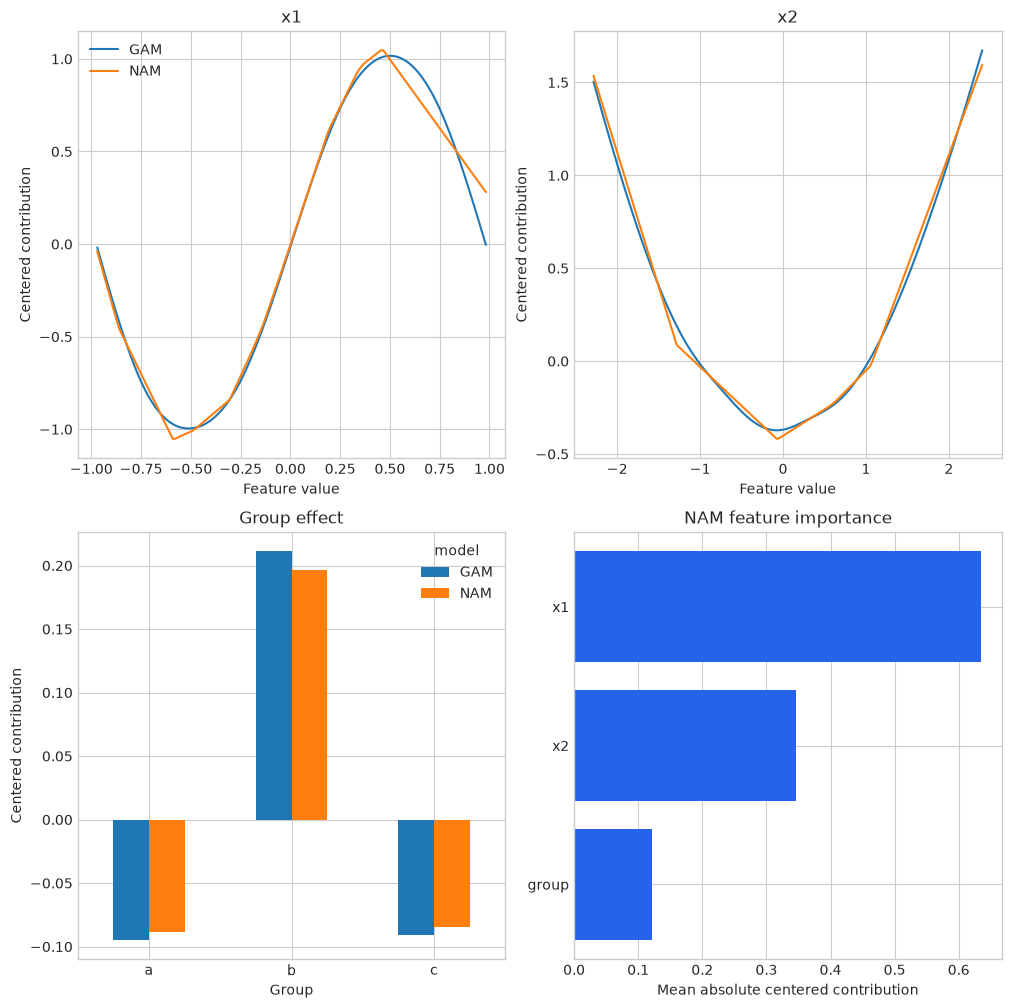

In [8]:
figure, axes = plt.subplots(2, 2, figsize=(10, 10), constrained_layout=True)
axes = axes.ravel()
for name, fitted in [("GAM", gam), ("NAM", nam)]:
    effects = fitted.predict_components(X_train)
    for axis, feature in zip(axes[:2], ["x1", "x2"]):
        values = np.linspace(X_train[feature].quantile(0.01), X_train[feature].quantile(0.99), 160)
        grid = pd.DataFrame({"x1": np.full(160, X_train.x1.median()),
                             "x2": np.full(160, X_train.x2.median()),
                             "group": pd.Categorical(["a"] * 160, categories=X["group"].cat.categories)})
        grid[feature] = values
        key = next(key for key in effects.terms if feature in key)
        contribution = np.asarray(fitted.predict_components(grid).terms[key]).reshape(-1)
        contribution -= np.asarray(effects.terms[key]).mean()
        axis.plot(values, contribution, label=name)
        axis.set(title=feature, xlabel="Feature value", ylabel="Centered contribution")
# Use source-feature grouping for encoded categorical terms.
category_rows = []
for name, fitted in [("GAM", gam), ("NAM", nam)]:
    parts = fitted.predict_components(X_train)
    category_effect = sum(np.asarray(value).reshape(-1) for key, value in parts.terms.items() if "group" in key)
    category_effect -= category_effect.mean()
    for group in X["group"].cat.categories:
        category_rows.append({"model": name, "group": group,
                              "effect": category_effect[X_train["group"] == group].mean()})
pd.DataFrame(category_rows).pivot(index="group", columns="model", values="effect").plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Group effect", xlabel="Group", ylabel="Centered contribution")
axes[0].legend()

importance = nam.term_importance(X_test, center=True, reference_X=X_train).sort_values("importance")
axis = axes[3]
axis.barh(importance["term"], importance["importance"], color=COLORS[0])
axis.set(title="NAM feature importance", xlabel="Mean absolute centered contribution")
for plot_axis in figure.axes:
    plot_axis.set_box_aspect(1)
plt.show()
plt.close(figure)


## 6. Link scale and response scale

With an identity link, a one-unit term contribution is a one-unit change
in the conditional mean. With a nonlinear inverse link, contributions
add before transformation. For a logistic model,

$$p_i=\frac{1}{1+\exp(-\eta_i)}.$$

Applying the logistic function to each term separately and adding the
results is mathematically wrong. The response-scale effect of a term
depends on the row's other terms through the current value of $\eta$.


In [9]:
from nampy.models import GAMClassifier

binary_train = X.iloc[train_index].assign(y=y_binary[train_index])
classifier = GAMClassifier(
    formula="y ~ s(x1, bs='cr', k=8) + s(x2, bs='cr', k=8) + group"
).fit(binary_train, binary_train["y"])

gaussian_components = gam.predict_components(X_test)
logistic_components = classifier.predict_components(X_test)
gaussian_components.validate_additive_reconstruction()
logistic_components.validate_additive_reconstruction()

display(pd.DataFrame({
    "scale": ["Gaussian link", "Gaussian response", "logistic link", "class-1 probability"],
    "first prediction": [
        gaussian_components.link[0], gaussian_components.response[0],
        logistic_components.link[0], logistic_components.response[0],
    ],
}))


,scale,first prediction
0,Gaussian link,0.693342
1,Gaussian response,0.693342
2,logistic link,0.834848
3,class-1 probability,0.697379


### See the link transform

The curve maps the additive log-odds predictor to a probability. The same
change in log-odds has a smaller probability effect near zero or one than
near the middle of the curve.

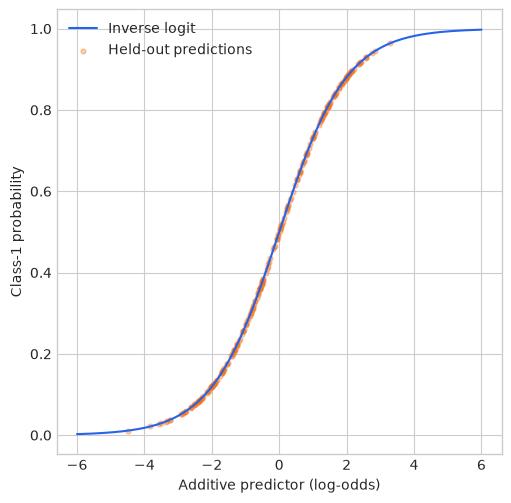

In [10]:
figure, axis = plt.subplots(figsize=(5, 5), constrained_layout=True)
eta = np.linspace(-6, 6, 200)
axis.plot(eta, 1 / (1 + np.exp(-eta)), color=COLORS[0], label="Inverse logit")
axis.scatter(np.asarray(logistic_components.link).reshape(-1),
             np.asarray(logistic_components.response).reshape(-1),
             s=12, alpha=0.35, color=COLORS[1], label="Held-out predictions")
axis.set(xlabel="Additive predictor (log-odds)", ylabel="Class-1 probability")
axis.legend()
for plot_axis in figure.axes:
    plot_axis.set_box_aspect(1)
plt.show()
plt.close(figure)


### Check probability calibration

Calibration compares predicted probabilities with observed class frequencies
in held-out bins. Points near the diagonal indicate agreement in those bins.
This small test sample makes the curve noisy, so departures should motivate
further validation rather than an immediate conclusion about calibration.

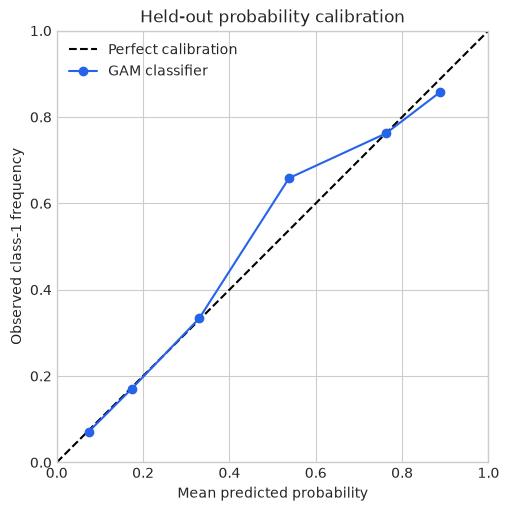

In [11]:
from sklearn.calibration import calibration_curve

probability = np.asarray(logistic_components.response).reshape(-1)
observed_frequency, mean_probability = calibration_curve(
    y_binary[test_index], probability, n_bins=6, strategy="quantile"
)
figure, axis = plt.subplots(figsize=(5, 5), constrained_layout=True)
axis.plot([0, 1], [0, 1], "--", color="black", label="Perfect calibration")
axis.plot(mean_probability, observed_frequency, "o-", color=COLORS[0], label="GAM classifier")
axis.set(xlabel="Mean predicted probability", ylabel="Observed class-1 frequency",
         title="Held-out probability calibration", xlim=(0, 1), ylim=(0, 1))
axis.set_box_aspect(1)
axis.legend()
plt.show()
plt.close(figure)


## 7. Scikit-learn integration

Because preprocessing is already part of neural estimators, they can be
placed directly in a pipeline. GAM array adapters also compose with
external transformers. Cross-validation estimates generalization;
`GridSearchCV` clones the estimator for every candidate, so all modeling
choices must be constructor parameters. Custom scorers should respect the
task's response scale.

Cross-validation repeatedly fits on one subset and evaluates on another.
Any learned preprocessing must be fitted within each training fold, otherwise
information from the validation rows leaks into the fit. For regression,
$R^2=1-\sum_i(y_i-\hat y_i)^2/\sum_i(y_i-\bar y)^2$ compares predictions
with a constant baseline; it can be negative on held-out data.


In [12]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline

numeric_X = X[["x1", "x2"]]
pipeline = Pipeline([
    ("model", GAMRegressor(optimize_smoothing=False, smoothing_method="fixed", smoothing_params=[0.7, 0.7])),
])
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(pipeline, numeric_X, y_reg, cv=cv, scoring="r2")

search = GridSearchCV(
    pipeline,
    {"model__k": [6, 9]},
    cv=cv,
    scoring="neg_mean_squared_error",
).fit(numeric_X, y_reg)

display({
    "mean CV R2": float(cv_scores.mean()),
    "best parameters": search.best_params_,
    "clone class": type(clone(nam)).__name__,
})


{'mean CV R2': 0.9325745132789274,
 'best parameters': {'model__k': 9},
 'clone class': 'NAMRegressor'}

### Compare validation folds

Each point is a held-out fold score. Differences between folds show
sensitivity to the split, while the dashed line summarizes their mean.
Ten folds show variation across more held-out subsets. Each point still
reflects a different sample; the connecting line is a visual guide, not a
learning curve or a confidence interval.

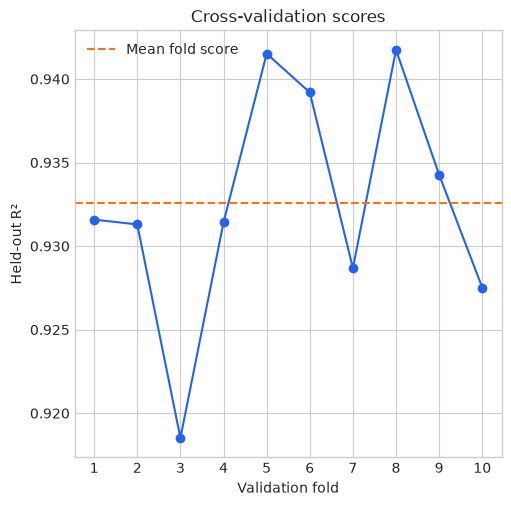

In [13]:
figure, axis = plt.subplots(figsize=(5, 5), constrained_layout=True)
fold = np.arange(1, len(cv_scores) + 1)
axis.plot(fold, cv_scores, "o-", color=COLORS[0])
axis.axhline(cv_scores.mean(), linestyle="--", color=COLORS[1], label="Mean fold score")
axis.set(xlabel="Validation fold", ylabel="Held-out R²", title="Cross-validation scores", xticks=fold)
axis.set_box_aspect(1)
axis.legend()
plt.show()
plt.close(figure)


## Continue learning

**Recommended next:** [Classify a real dataset](05_real_data_classification.ipynb)
for missing values, a baseline, probabilities, and complete persistence.

Choose a branch afterwards:
- [Statistical GAMs](../tutorials/first_gam.rst): smooths, diagnostics, constraints.
- [GAM and NAM comparison](../tutorials/gam_nam.rst): compare representations.
- [Changing variability](../tutorials/changing_variability.rst): location and spread.
